# P01 — Normal operating patterns

This notebook presents the P01 normal-operation analysis. It reads the saved, immutable run artefacts; the production pipeline remains in `src/sfsa/`.

The controlled-fault dataset is from one HVAC facility. These patterns describe this dataset, not every building.

## Reproduce P01

Run this command from the repository root to create a new timestamped result folder, then rerun the cells below:

```bash
sfsa patterns \
  --building-config configs/buildings/rbc_ashrae1312_real.yaml \
  --experiment-config configs/experiments/P01_normal_operating_patterns.yaml \
  --results-root results/final_runs
```

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'results' / 'final_runs'

def latest_run(experiment):
    matches = sorted(RESULTS.glob(f'*_{experiment}'))
    if not matches:
        raise FileNotFoundError(f'No completed run found for {experiment}.')
    return matches[-1]

run_dir = latest_run('P01_normal_operating_patterns')
print(f'Using: {run_dir.name}')

Using: 20261026T140051Z_rbc_ashrae1312_real_P01_normal_operating_patterns


In [2]:
quality = json.loads((run_dir / 'normal_mode_quality.json').read_text())
catalogue = pd.read_csv(run_dir / 'normal_mode_catalogue.csv')
profiles = pd.read_csv(run_dir / 'normal_mode_feature_profiles.csv')

display(pd.DataFrame([quality]))
display(catalogue)
display(profiles.head(20))

,clusters,controlled_fault_observations,feature_count,normal_observations,pca_explained_variance_ratio,silhouette_sample_rows,silhouette_score,stability_ari_mean,stability_repeats
0,4,70560,70,70560,"[0.3719362931458231, 0.1873983285460833]",2000,0.355423,0.79095,2


,normal_mode,baseline_rows,baseline_share,mean_mode_distance
0,0,31521,0.446726,4.980355
1,1,15612,0.221259,5.021124
2,2,8571,0.121471,4.710061
3,3,14856,0.210544,4.279122


,normal_mode,feature,centre_raw_value,centre_standardised_value
0,0,HWP-GPM,0.207008,-0.361941
1,0,CHWP-GPM,7.797435,-0.522168
2,0,RFCFMLAG,0.000000,0.000000
3,0,RMT-CFM,48.999033,-0.995202
4,0,SA-CFM,41.148420,-1.006405
5,0,RA-CFM,11.410005,-1.083223
6,0,OA-CFM,6.270046,-0.785506
7,0,SA-TEMP,68.925682,0.917235
8,0,MA-TEMP,67.545578,0.258893
9,0,RA-TEMP,72.460970,0.472868


## Visual evidence

The PCA figure is a two-dimensional view of the selected normal-operation features. It supports interpretation; it is not itself an anomaly detector.

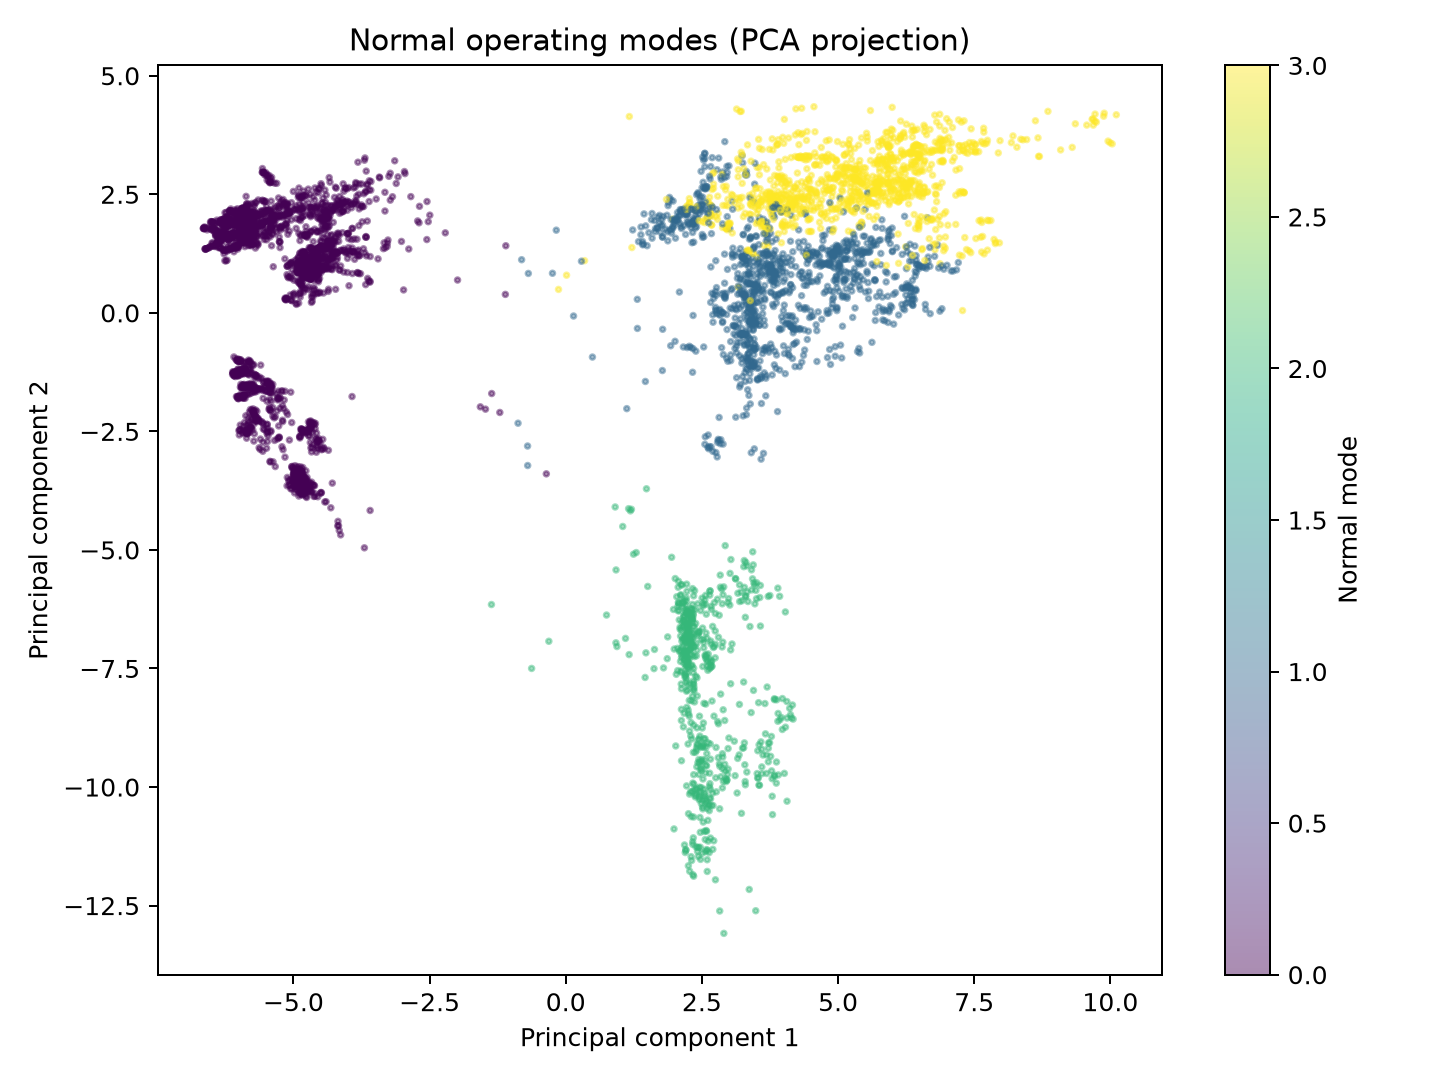

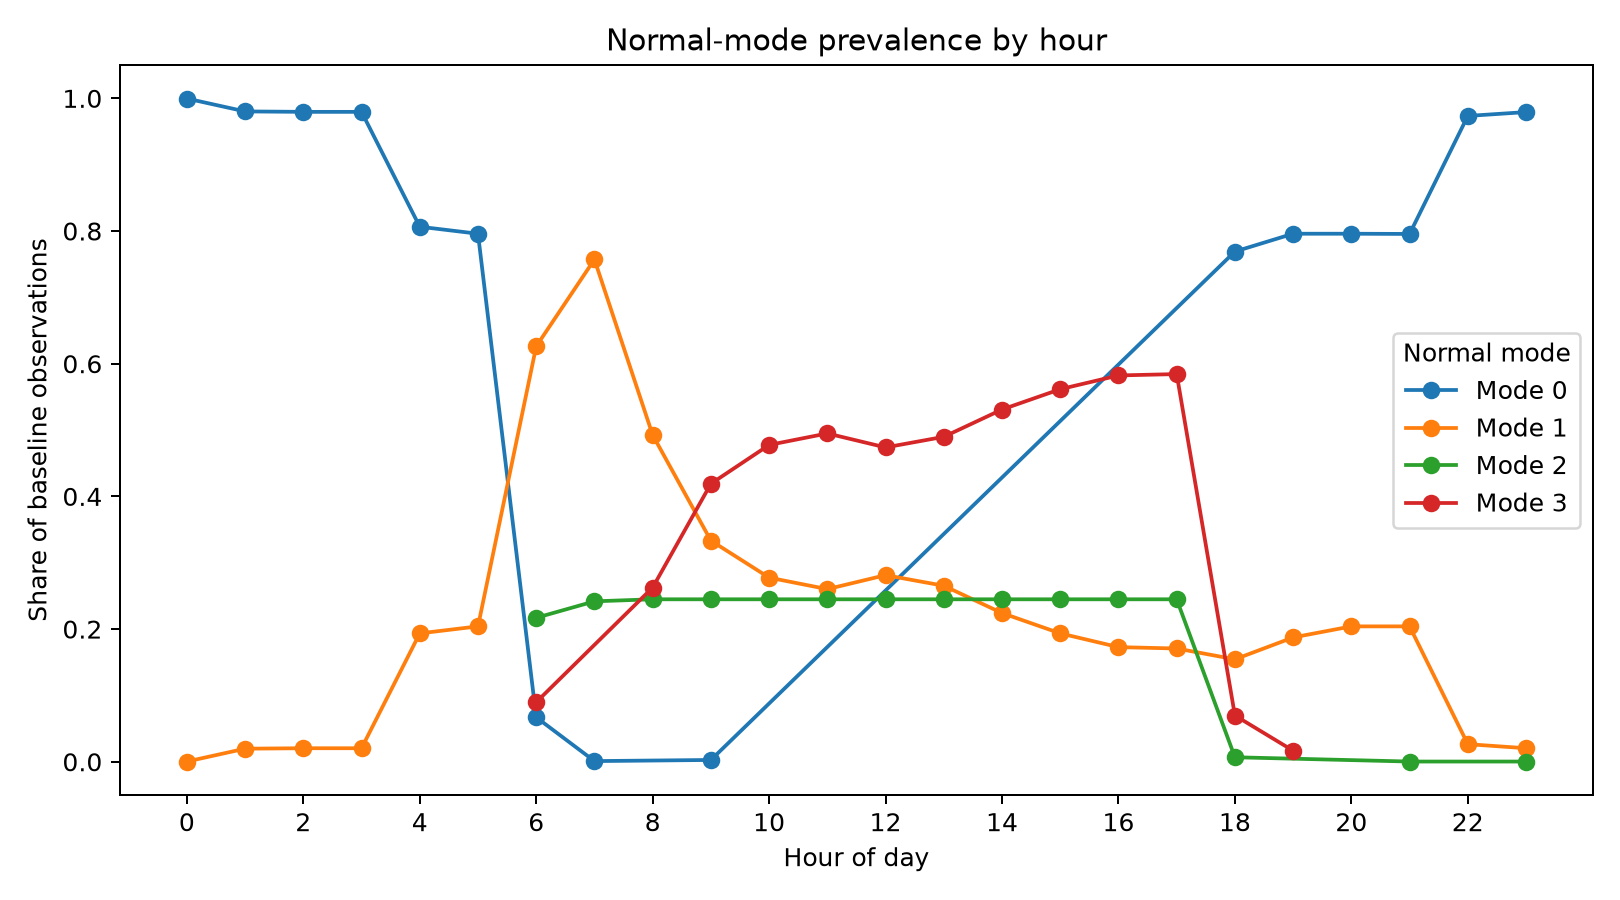

In [3]:
display(Image(filename=run_dir / 'figures' / 'normal_modes_pca.png'))
display(Image(filename=run_dir / 'figures' / 'normal_modes_by_hour.png'))